# 24 — Mức sẵn sàng parity Python/C

> **Phạm vi:** proof of concept phân loại motion phenotype dựa trên proxy label — KHÔNG phải bộ phân loại an toàn hàng hải đã xác thực. Golden vector đã chuẩn bị **không** có nghĩa parity Python/C hay triển khai ESP32 đã được kiểm chứng. Trạng thái: `PYTHON_REFERENCE_READY` · `C_PARITY_PENDING`.

**Mục tiêu.** Trình bày thiết kế dung sai theo feature, harness so sánh, mô phỏng float32 (để *hiệu chỉnh* dung sai — **không phải kết quả C**), ma trận phát hiện lỗi, kịch bản file hỏng, và trạng thái ba mức kiểm chứng.

**Không có kết quả C/C++ thật nào trong notebook này.** Mọi “PASS” được gắn nhãn `PYTHON_SELF_CONSISTENCY_*` hoặc `FLOAT32_EMULATION_*`.

In [1]:
from pathlib import Path
import json, sys, hashlib, math, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "ml/parity/golden.py").is_file():
    REPO_ROOT = next(p for p in Path.cwd().parents if (p / "ml/parity/golden.py").is_file())
sys.path.insert(0, str(REPO_ROOT))
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.unicode_minus": False, "figure.dpi": 100, "font.size": 9})
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
from ml.parity import compare, interchange, float32_probe, readiness
from ml.parity.golden import SYNTHETIC_ROOT, TOLERANCE_PATH, MANIFEST
from ml.parity.contract import FEATURE_ORDER
report = json.loads((REPO_ROOT / readiness.REPORT_JSON).read_text(encoding="utf-8"))
tol = json.loads((REPO_ROOT / TOLERANCE_PATH).read_text(encoding="utf-8"))
current_manifest = hashlib.sha256((REPO_ROOT / MANIFEST).read_bytes()).hexdigest()
print("Trạng thái:", report["status"], "| báo cáo dùng manifest hiện tại:", report["golden_manifest_sha256"] == current_manifest)
print("Kết quả C thật đã nộp:", report["c_results_submitted"] or "không có")

Trạng thái: ['PYTHON_REFERENCE_READY', 'C_PARITY_PENDING'] | báo cáo dùng manifest hiện tại: True
Kết quả C thật đã nộp: không có


## 1. Ba mức kiểm chứng

In [2]:
display(pd.Series(report["levels"], name="trạng thái").to_frame())

,trạng thái
level_1_python_reference,Golden do extractor production tạo; kiểm tra giải tích độc lập + cross-check feature table + test.
level_2_python_c_parity,CHƯA CÓ kết quả C thật — C_PARITY_PENDING.
level_3_esp32_sensor_to_model,CHƯA ĐÁNH GIÁ. Level 2 không chứng minh Level 3; lệch miền do chuỗi lọc firmware đã đo: POS 188 -> 4 (esp32_feature_...


> Level 2 không suy ra Level 3. Thí nghiệm đã có (`ml/reports/ml/esp32_feature_compatibility.md`): lọc Roll/Pitch Hohai bằng Butterworth bậc 2, 0,5 Hz như chuỗi firmware hiện tại làm số dự đoán POS của RF giảm **188 → 4**.

## 2. Dung sai theo feature

$$|c-p| \le a + r\,|p| + s\,S,\qquad S=\max|x| \text{ của tín hiệu/cửa sổ mà feature dùng}$$

Hạng $s\,S$ phản ánh việc sai số làm tròn float32 tỷ lệ với **độ lớn đầu vào** (ví dụ std nhỏ của tín hiệu có offset lớn). R² và ratio có điều kiện REVIEW khi bài toán ill-conditioned. Đây là **đề xuất kỹ thuật**, chưa đo trên thiết bị.

In [3]:
classes = pd.DataFrame(tol["classes"]).T
classes["feature"] = [", ".join(f for f, c in tol["feature_class"].items() if c == k) for k in classes.index]
display(classes[["abs_floor", "rel", "scale_rel", "feature", "rationale"]])
display(pd.Series(tol["review_conditions"]).to_frame("điều kiện REVIEW"))

,abs_floor,rel,scale_rel,feature,rationale
count_ratio,0.000001,0.0,0.0,roll_dominant_sign_ratio_180,Đếm dấu trên giá trị float32 chính xác; chỉ sai số chia.
difference_rms,0.0,0.00002,0.000002,roll_diff_rms_60,Hiệu hai mẫu float32 kề nhau rồi RMS.
dispersion,0.0,0.00002,0.00005,"pitch_std_60, roll_segment_mean_std_180, roll_std_60",Phương sai có triệt tiêu khi |mean| >> std; hạng tỷ lệ theo biên độ đầu vào. Vẫn đủ chặt để phân biệt std quần thể/m...
extremum,0.0,0.0,0.0,"pitch_peak_to_peak_60, roll_abs_max_60, roll_peak_to_peak_60",Chọn đúng một giá trị float32 đầu vào (abs_max) hoặc một phép trừ (peak-to-peak): gần như chính xác.
mean,0.0,0.0,0.00002,"roll_mean_180, roll_mean_60, roll_mean_abs_180","Tổng N <= 1800 phần tử float32: sai số điển hình ~sqrt(N)·u ≈ 2.5e-6, chặn xấu N·u ≈ 1.1e-4 nếu cộng tuần tự; đề xuấ..."
mean_difference,0.0,0.0,0.00004,roll_mean_shift_180,Hiệu hai mean block: cộng dồn sai số hai tổng.
quantile,0.0,0.000001,0.000004,"roll_abs_p95_60, roll_iqr_60, roll_median_180",Sắp xếp chính xác + một phép nội suy Type-7 (IQR thêm một phép trừ). Đủ chặt để bắt sai quy ước phân vị.
r_squared,0.002,0.0,0.0,roll_rms_trend_r2_180,Chỉ áp dụng khi SST/mean(r)^2 >= 1e-6; dưới mức đó R² ill-conditioned -> REVIEW.
ratio,0.0,0.00005,0.0,roll_rms_ratio_180,Tỷ số hai RMS: sai số tương đối cộng dồn của tử và mẫu.
rms,0.0,0.00002,0.000002,"pitch_rms_60, roll_rms_60, roll_rms_early_60, roll_rms_late_60","Tổng bình phương dương, không triệt tiêu; sai số tương đối theo giá trị."


,điều kiện REVIEW
roll_rms_ratio_180,"rms block đầu trong [eps/10, eps*10] -> REVIEW_ILL_CONDITIONED"
roll_rms_trend_r2_180,SST/mean(block_rms)^2 < 1e-06 -> REVIEW_ILL_CONDITIONED (giá trị và validity)


## 3. Mô phỏng float32 để hiệu chỉnh dung sai

`float32_probe` tính lại trong float32 với cộng tuần tự (kiểu vòng for C đơn giản), std hai lượt, sắp xếp + Type-7. Chỉ số cửa sổ và validity cửa sổ lấy từ golden. Thước đo: tỷ lệ $|Δ|/\text{cho phép}$ — dưới 1 là trong dung sai.

Kết luận: FLOAT32_EMULATION_PASS_WITH_REVIEW | đếm: {'PASS_STATUS_ONLY': 4708, 'PASS_VALUE': 6515, 'REVIEW_ILL_CONDITIONED': 1}


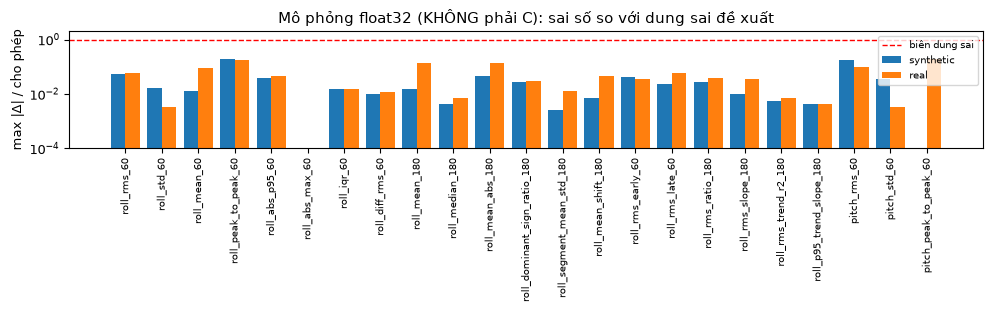

,case_id,endpoint_index,feature_name,expected_status,actual_status,actual_value,detail
10851,SYN30_permuted_blocks,2100,roll_rms_trend_r2_180,UNDEFINED_MATHEMATICALLY,VALID,0.0,ILL_CONDITIONED_R2: status UNDEFINED_MATHEMATICALLY vs VALID; quyết định phụ thuộc làm tròn (xem C02/C03)


In [4]:
expected, cases = compare.load_golden(REPO_ROOT, "synthetic")
emu = compare.compare_frames(expected, interchange.from_records(float32_probe.emulate_suite(REPO_ROOT, SYNTHETIC_ROOT)),
                             cases, float32_probe.emulation_metadata(None))
print("Kết luận:", emu["summary"]["verdict"], "| đếm:", emu["summary"]["outcome_counts"])
pf = pd.DataFrame(emu["summary"]["per_feature"]).set_index("feature_name")
real_pf = pd.DataFrame(report["suites"]["real"]["float32_emulation"]["per_feature"]).set_index("feature_name") if report["suites"].get("real", {}).get("available") else None
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(np.arange(23) - 0.2, pf.max_error_ratio.fillna(0), width=0.4, label="synthetic")
if real_pf is not None:
    ax.bar(np.arange(23) + 0.2, real_pf.max_error_ratio.fillna(0), width=0.4, label="real")
ax.axhline(1.0, color="red", lw=1, ls="--", label="biên dung sai")
ax.set_xticks(range(23)); ax.set_xticklabels(FEATURE_ORDER, rotation=90, fontsize=7); ax.set_yscale("log"); ax.set_ylim(1e-4, 2)
ax.set_ylabel("max |Δ| / cho phép"); ax.set_title("Mô phỏng float32 (KHÔNG phải C): sai số so với dung sai đề xuất"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
display(emu["rows"].loc[emu["rows"].outcome.eq("REVIEW_ILL_CONDITIONED"), ["case_id", "endpoint_index", "feature_name", "expected_status", "actual_status", "actual_value", "detail"]])

### Bằng chứng cho issue C03

SYN30 có ba block là hoán vị của cùng 600 giá trị. Python dùng `math.fsum` (tổng chính xác, không phụ thuộc thứ tự) nên ba RMS block trùng nhau tuyệt đối, SST = 0, R² UNDEFINED. Float32 cộng tuần tự cho ba RMS khác nhau ở chữ số thứ 7, SST vượt ngưỡng tuyệt đối $10^{-15}$, nên R² trở thành VALID dù không có ý nghĩa vật lý.

In [5]:
display(pd.Series(report["c03_evidence"]).to_frame("giá trị"))

,giá trị
case_id,SYN30_permuted_blocks
endpoint_index,2100
python_block_rms,"[1.490180883822287, 1.490180883822287, 1.490180883822287]"
python_sst,0.0
float32_block_rms,"[1.4901810884475708, 1.4901807308197021, 1.4901812076568604]"
float32_sst,0.0
sst_threshold,0.0


## 4. Ma trận phát hiện lỗi hiện thực C điển hình

Mỗi đột biến tái hiện một lỗi C thường gặp. Golden + dung sai phải đánh rớt **tất cả**; cột “case phát hiện” cho biết bao nhiêu case làm lộ lỗi.

,mutation,description_vi,verdict,fail_records,số case phát hiện
0,sample_std_ddof1,std mẫu (chia n-1) thay vì std quần thể,FLOAT32_EMULATION_FAIL,589,26
1,quantile_nearest_rank,phân vị nearest-rank thay vì Type-7,FLOAT32_EMULATION_FAIL,586,26
2,quantile_type6,phân vị Type-6 h=(n+1)p thay vì Type-7,FLOAT32_EMULATION_FAIL,529,25
3,window_includes_lower_bound,"cửa sổ [t-W, t) (lệch 1 mẫu) thay vì (t-W, t]",FLOAT32_EMULATION_FAIL,929,17
4,radians_input,dùng Roll/Pitch theo radian,FLOAT32_EMULATION_FAIL,4473,30
5,diff_per_second,roll_diff_rms_60 chia cho dt (deg/s) thay vì deg/mẫu,FLOAT32_EMULATION_FAIL,398,27
6,slope_per_second,slope không nhân 60 (deg/s thay vì deg/phút),FLOAT32_EMULATION_FAIL,95,14
7,p95_without_abs,P95 trên x thay vì |x|,FLOAT32_EMULATION_FAIL,333,20
8,centered_rms,RMS quanh mean (thực chất là std) thay vì RMS gồm offset,FLOAT32_EMULATION_FAIL,486,15
9,swap_roll_pitch_rms,đảo vị trí roll_rms_60 (0) và pitch_rms_60 (20),FLOAT32_EMULATION_FAIL,916,30


Mọi đột biến bị phát hiện: True


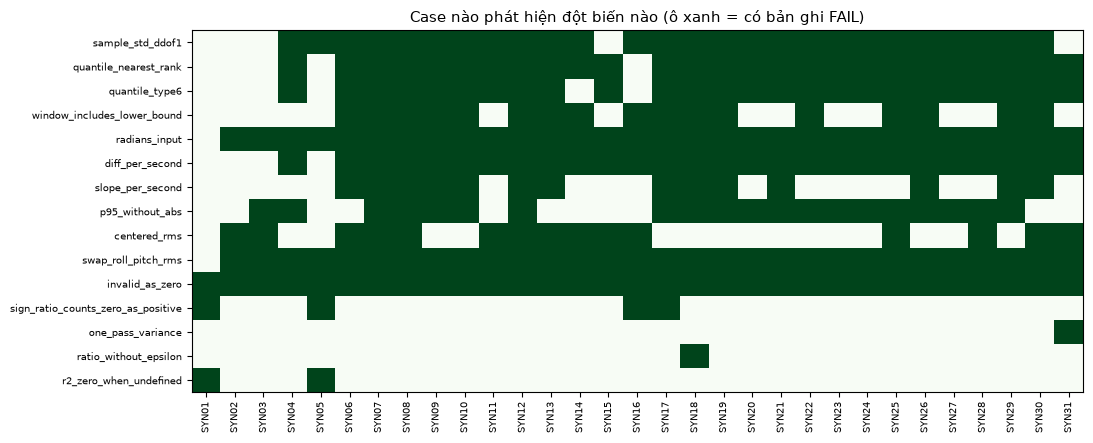

In [6]:
matrix = pd.DataFrame(report["suites"]["synthetic"]["mutation_matrix"])
matrix["số case phát hiện"] = matrix.detecting_cases.map(len)
display(matrix[["mutation", "description_vi", "verdict", "fail_records", "số case phát hiện"]])
print("Mọi đột biến bị phát hiện:", report["suites"]["synthetic"]["all_mutations_detected"])
case_ids = sorted(cases)
grid = np.array([[cid in m["detecting_cases"] for cid in case_ids] for m in report["suites"]["synthetic"]["mutation_matrix"]], dtype=int)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.imshow(grid, cmap="Greens", aspect="auto")
ax.set_yticks(range(len(matrix))); ax.set_yticklabels(matrix.mutation, fontsize=7)
ax.set_xticks(range(len(case_ids))); ax.set_xticklabels([c.split("_")[0] for c in case_ids], rotation=90, fontsize=7)
ax.set_title("Case nào phát hiện đột biến nào (ô xanh = có bản ghi FAIL)"); plt.tight_layout(); plt.show()

## 5. Kịch bản file đầu ra hỏng

Harness phải từ chối: thiếu/trùng/thừa bản ghi, sai `input_sha256`, sai `schema_version`, tên lệch index, NaN hoặc rỗng nhưng báo VALID, ghi 0 cho feature không hợp lệ, đổi status, status lạ, endpoint lệch, giá trị vượt dung sai — và **chấp nhận** giá trị lệch nửa dung sai.

In [7]:
display(pd.DataFrame(report["suites"]["synthetic"]["corruption_scenarios"]))

,scenario,expected_outcome,verdict,outcome_counts,behaved_as_expected
0,missing_case,MISSING,PYTHON_SELF_CONSISTENCY_FAIL,{'MISSING': 368},True
1,missing_rows,MISSING,PYTHON_SELF_CONSISTENCY_FAIL,{'MISSING': 3},True
2,duplicate_rows,DUPLICATE,PYTHON_SELF_CONSISTENCY_FAIL,{'DUPLICATE': 2},True
3,extra_case,EXTRA,PYTHON_SELF_CONSISTENCY_FAIL,{'EXTRA': 1},True
4,wrong_input_sha256,FAIL_INPUT_SHA256,PYTHON_SELF_CONSISTENCY_FAIL,{'FAIL_INPUT_SHA256': 368},True
5,wrong_schema_version,FAIL_SCHEMA_VERSION,PYTHON_SELF_CONSISTENCY_FAIL,{'FAIL_SCHEMA_VERSION': 1},True
6,feature_names_shifted_by_one,FAIL_FEATURE_NAME_ORDER,PYTHON_SELF_CONSISTENCY_FAIL,{'FAIL_FEATURE_NAME_ORDER': 23},True
7,nan_reported_as_valid,FAIL_VALID_NOT_FINITE,PYTHON_SELF_CONSISTENCY_FAIL,{'FAIL_VALID_NOT_FINITE': 1},True
8,empty_value_reported_as_valid,FAIL_VALID_NOT_FINITE,PYTHON_SELF_CONSISTENCY_FAIL,{'FAIL_VALID_NOT_FINITE': 1},True
9,invalid_written_as_zero,FAIL_INVALID_HAS_VALUE,PYTHON_SELF_CONSISTENCY_FAIL,{'FAIL_INVALID_HAS_VALUE': 1},True


## 6. Quy trình M1 sẽ chạy (minh họa bằng self-consistency, KHÔNG phải C)

Ghi golden ra đúng định dạng trao đổi rồi chạy harness như M1 sẽ chạy với file C. Kết luận phải mang nhãn `PYTHON_SELF_CONSISTENCY_PASS`, `is_c_parity_evidence = False`.

In [8]:
records = readiness._golden_records(REPO_ROOT, "synthetic")
with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    interchange.write_csv(records, tmp / "synthetic.csv")
    meta = interchange.metadata_template(); meta["producer"] = {"kind": "python_reference_self_consistency", "name": "notebook 24"}
    meta["golden_manifest_sha256"] = current_manifest
    (tmp / "metadata.json").write_text(json.dumps(meta), encoding="utf-8")
    result = compare.run_comparison(REPO_ROOT, "synthetic", tmp / "synthetic.csv", tmp / "metadata.json", tmp / "out")
    print({k: result["summary"][k] for k in ("verdict", "is_c_parity_evidence", "expected_records", "candidate_records", "outcome_counts")})
    print((tmp / "out/comparison_report.md").read_text(encoding="utf-8")[:900])

{'verdict': 'PYTHON_SELF_CONSISTENCY_PASS', 'is_c_parity_evidence': False, 'expected_records': 11224, 'candidate_records': 11224, 'outcome_counts': {'PASS_STATUS_ONLY': 4709, 'PASS_VALUE': 6515}}
# So sánh parity — suite synthetic

- Kết luận: **PYTHON_SELF_CONSISTENCY_PASS**
- Loại nguồn kết quả: `python_reference_self_consistency` — bằng chứng parity C: **không**
- Bản ghi golden: 11224; bản ghi ứng viên: 11224
- FAIL: 0; REVIEW: 0; cảnh báo reason_code: 0
- Case thiếu: không; case thừa: không
- Level 2 (cùng chuỗi Roll/Pitch đầu vào). Không chứng minh Level 3 (IMU thật, ước lượng góc, lọc trên ESP32).

## Đếm kết quả

| Kết quả | Số bản ghi |
|---|---:|
| PASS_STATUS_ONLY | 4709 |
| PASS_VALUE | 6515 |

## Theo feature

| # | Feature | Lớp dung sai | Pass | Fail | Review | Max |Δ| | Max |Δ|/cho phép |
|---:|---|---|---:|---:|---:|---:|---:|
| 0 | `roll_rms_60` | rms | 488 | 0 | 0 | 0 | 0 |
| 1 | `roll_std_60` | dispersion | 488 | 0 | 0 | 0 | 0 |
| 2 | `roll_mean_60` | mean | 488 | 0

## Diễn giải

- **PYTHON_REFERENCE_READY:** golden đầy đủ, có checksum, tái tạo được; harness, định dạng trao đổi và dung sai đã sẵn sàng.
- **C_PARITY_PENDING:** chưa có đầu ra C/C++ thật. Không có kết luận parity Python/C nào được đưa ra.
- Dung sai đề xuất có biên an toàn khoảng 5 lần so với mô phỏng float32 trung thực, đồng thời bắt được 15/15 lỗi hiện thực điển hình.
- C03 đã được tái hiện bằng số: cần M1 cộng dồn bằng double và nhóm chốt ngưỡng SST tương đối.

## Hạn chế

- Mô phỏng float32 là Python: không tái hiện trình biên dịch Xtensa, `madd.s` (FMA), cờ tối ưu, hay thư viện `sqrtf` của ESP-IDF.
- Probe dùng validity cửa sổ của golden, nên logic coverage/gap của C chỉ được kiểm khi có đầu ra C thật trên SYN20–SYN27.
- Không có số đo RAM/Flash/latency trên thiết bị; ước lượng ở `esp32_feature_compatibility.md` vẫn là `ESTIMATE_NOT_MEASURED_ON_DEVICE`.

## Ghi chú vấn đáp

- *Tại sao không tự viết bản C để chứng minh parity?* Firmware là trách nhiệm của M1; một bản C do M2 viết để tự kiểm sẽ không độc lập và không phải mã chạy trên thiết bị.
- *REVIEW có làm mềm tiêu chuẩn không?* Không: REVIEW chỉ áp dụng cho R²/ratio khi bài toán ill-conditioned đã được đánh dấu trước trong golden; R² ngoài [0, 1], NaN báo VALID, 0 thay cho invalid vẫn luôn FAIL.
- *Khi nào được nói “parity đạt”?* Khi file đầu ra từ mã C thật (`producer.kind = independent_c_implementation`, có commit/trình biên dịch) qua cả suite synthetic và real không có FAIL. Kể cả khi đó, Level 3 vẫn phải kiểm riêng.